# Étape 10.3 : un panier par facteur, l'argent réparti par GARCH-ERC

Jusqu'ici (étapes 9 et 10.2), on **intègre** les facteurs : un seul score par action, $S = \sum_k w_k z_k$, puis un seul portefeuille. Ici, on **mélange** : un panier d'actions par facteur, puis on répartit l'argent entre les paniers avec les poids GARCH-ERC de l'étape 10.2.

Tout le reste est identique : mêmes actions, mêmes z-scores, même sélection (30 %, zone tampon à 40 %), même pondération capitalisation × (1 + z), même plafond de 10 %, mêmes frais.

## 1. Données et outils des étapes 9 et 10.2

In [1]:
import io
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.optimize import minimize
from scipy.stats import norm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
FIG = ROOT / "docs" / "figures"

pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
from arch import arch_model

In [2]:
base = pd.read_csv(ROOT / "data" / "processed" / "zscores_sp500_mensuels.csv.gz")
base["mois"] = pd.PeriodIndex(base["mois"], freq="M")
base = base.set_index(["mois", "ticker"]).sort_index()

ajustes = pd.read_csv(RAW / "sp500_cours_ajustes_mensuels.csv", index_col=0)
ajustes.index = pd.PeriodIndex(ajustes.index.astype(str).str[:7], freq="M")
rendements = ajustes.pct_change(fill_method=None)


def lire_bloc_mensuel(chemin_zip):
    with zipfile.ZipFile(chemin_zip) as z:
        texte = z.read(z.namelist()[0]).decode("latin-1")
    lignes = texte.splitlines()
    debut = next(i for i, l in enumerate(lignes) if l.startswith(","))
    bloc = [lignes[debut]]
    for l in lignes[debut + 1:]:
        if not l.strip() or not l.strip()[0].isdigit():
            break
        bloc.append(l)
    df = pd.read_csv(io.StringIO("\n".join(bloc)), index_col=0)
    df.columns = df.columns.str.strip()
    df.index = pd.PeriodIndex(df.index.astype(str), freq="M")
    return df.astype(float) / 100


facteurs = lire_bloc_mensuel(RAW / "F-F_Research_Data_5_Factors_2x3_CSV.zip").join(
    lire_bloc_mensuel(RAW / "F-F_Momentum_Factor_CSV.zip"), how="inner")
rf = facteurs["RF"]

etf = pd.read_csv(RAW / "cours_mensuels.csv", index_col=0)[["SPY", "RSP"]]
etf.index = pd.PeriodIndex(etf.index, freq="M")
rend_etf = etf.pct_change()

mois = base.index.get_level_values("mois").unique()
print(f"z-scores : {mois[0]} à {mois[-1]}, {len(mois)} mois")

z-scores : 2012-02 à 2026-08, 175 mois


In [3]:
STYLES = {"z_smb": "SMB", "z_hml": "HML", "z_rmw": "RMW", "z_cma": "CMA", "z_mom": "Mom"}
Z = base[list(STYLES)]

In [4]:
def poids_erc(cov):
    # Spinu (2013) : le minimum de 1/2 y'Σy - (1/n) Σ log(y) donne des contributions au risque égales.
    n = len(cov)
    y0 = 1 / np.sqrt(np.diag(cov))
    y = minimize(lambda y: 0.5 * y @ cov @ y - np.log(y).sum() / n, y0,
                 jac=lambda y: cov @ y - 1 / (n * y), bounds=[(1e-10, None)] * n, method="L-BFGS-B").x
    return y / y.sum()


def contributions(w, cov):
    rc = w * (cov @ w)
    return rc / rc.sum()


poids = {}
for m in mois:
    histo = facteurs.loc[:m, list(STYLES.values())].iloc[-60:]
    poids[m] = poids_erc(histo.cov().values)
poids = pd.DataFrame(poids, index=list(STYLES.values())).T

# Contrôle : contributions au risque au dernier mois
cov_fin = facteurs.loc[:mois[-1], list(STYLES.values())].iloc[-60:].cov().values
print("Contributions au risque (dernier mois) :", np.round(contributions(poids.iloc[-1].values, cov_fin), 3))
print("\nPoids ERC des facteurs dans le score, résumé sur la période :")
poids.describe().loc[["mean", "min", "max"]].round(2)

Contributions au risque (dernier mois) : [0.2 0.2 0.2 0.2 0.2]

Poids ERC des facteurs dans le score, résumé sur la période :


,SMB,HML,RMW,CMA,Mom
mean,0.23,0.13,0.30,0.18,0.17
min,0.17,0.08,0.25,0.12,0.08
max,0.32,0.22,0.36,0.23,0.22


In [5]:
def score_final(w):
    # w : DataFrame (mois x facteurs) de poids
    wl = w.reindex(Z.index.get_level_values("mois")).set_axis(Z.index)
    wl.columns = list(STYLES)
    s = (Z.fillna(0) * wl).sum(axis=1)[Z.notna().sum(axis=1) >= 3]
    return s.groupby(level="mois").transform(lambda x: (x - x.mean()) / x.std())


egal = pd.DataFrame(0.2, index=mois, columns=list(STYLES.values()))
scores = pd.DataFrame({"score_equipondere": score_final(egal), "score_erc": score_final(poids)})
print(f"{len(scores):,}".replace(",", " "), "scores (mois, action)")
print(f"Corrélation entre les deux scores : {scores.corr().iloc[0, 1]:.2f}")
scores.to_csv(ROOT / "data" / "processed" / "scores_finaux_sp500.csv.gz", float_format="%.5g")

72 741 scores (mois, action)
Corrélation entre les deux scores : 0.92


In [6]:
capi = base["capitalisation"]
PLAFOND = 0.10


def plafonner(w, plafond=PLAFOND):
    # Aucune action au-dessus du plafond ; l'excédent est redistribué aux autres, au prorata.
    w = w / w.sum()
    while (w > plafond + 1e-12).any():
        trop = w > plafond
        excedent = (w[trop] - plafond).sum()
        w[trop] = plafond
        w[~trop] += excedent * w[~trop] / w[~trop].sum()
    return w


def poids_cibles(score, seuil=0.30, tampon=0.40, ponderation="capi_score"):
    cibles, tenus = {}, set()
    for m in mois[:-1]:
        s = score.xs(m).dropna()
        c = capi.xs(m).reindex(s.index).dropna()
        s = s[c.index]
        rang = s.rank(ascending=False, pct=True)
        selection = set(rang[rang <= seuil].index)
        if tampon:
            selection |= set(rang[rang <= tampon].index) & tenus
        selection = sorted(selection)
        tenus = set(selection)
        if ponderation == "egale":
            w = pd.Series(1.0, index=selection)
        elif ponderation == "capi":
            w = c[selection]
        else:
            w = c[selection] * (1 + s[selection]).clip(lower=0)
        cibles[m] = plafonner(w)
    return cibles

In [7]:
def backtest(cibles, frais=0.0010):
    lignes, derive, manquants = {}, pd.Series(dtype=float), 0
    for m, w in cibles.items():
        rotation = w.subtract(derive, fill_value=0).abs().sum()
        r = rendements.loc[m + 1].reindex(w.index)
        manquants += int(r.isna().sum())
        r = r.fillna(0)
        brut = float((w * r).sum())
        lignes[m + 1] = {"brut": brut, "rotation": rotation, "net": brut - frais * rotation}
        derive = w * (1 + r)
        derive = derive / derive.sum()
    sortie = pd.DataFrame(lignes).T
    sortie.attrs["manquants"] = manquants
    return sortie


def univers_capi():
    return {m: capi.xs(m).dropna() / capi.xs(m).dropna().sum() for m in mois[:-1]}

In [8]:
def test_moyenne(a):
    m = sm.OLS(a.values, np.ones(len(a))).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
    return m.params[0], m.tvalues[0], m.pvalues[0]


def indices_bootstrap(n, bloc_moyen, rng):
    idx = np.empty(n, dtype=int)
    idx[0] = rng.integers(n)
    for i in range(1, n):
        idx[i] = rng.integers(n) if rng.random() < 1 / bloc_moyen else (idx[i - 1] + 1) % n
    return idx


def sharpe(x, r_f):
    e = x - r_f
    return e.mean() / e.std() * np.sqrt(12)


def bootstrap(strat, bench, n_tirages=5000, bloc_moyen=6, graine=0):
    rng = np.random.default_rng(graine)
    s, b, f = strat.values, bench.values, rf.reindex(strat.index).values
    actif, d_sharpe = [], []
    for _ in range(n_tirages):
        i = indices_bootstrap(len(s), bloc_moyen, rng)
        actif.append((s[i] - b[i]).mean() * 12)
        d_sharpe.append(sharpe(s[i], f[i]) - sharpe(b[i], f[i]))
    return np.percentile(actif, [2.5, 97.5]), np.percentile(d_sharpe, [2.5, 97.5])

In [9]:
SURFACE, TEXTE, TEXTE2, GRILLE = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLEU, ORANGE, AQUA, JAUNE, MAGENTA, VERT = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"
GRIS = "#8d8c88"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10,
    "text.color": TEXTE, "axes.labelcolor": TEXTE2, "xtick.color": TEXTE2, "ytick.color": TEXTE2,
    "axes.edgecolor": GRILLE, "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})


def sauver(fig, nom):
    fig.savefig(FIG / nom, dpi=200, bbox_inches="tight")


def virgule(fmt):
    return plt.FuncFormatter(lambda v, _: fmt.format(v).replace(".", ",").replace("-", "−"))


COULEURS = {"Score équipondéré": BLEU, "Score ERC": ORANGE, "Univers (capitalisation)": TEXTE2, "SPY": GRIS}

### Les poids GARCH-ERC de l'étape 10.2

Volatilité de chaque facteur de Fama et French prévue pour le mois suivant par un GARCH(1,1) de Student (paramètres ré-estimés chaque décembre), corrélations des 60 derniers mois, puis poids ERC.

In [10]:
FACT = list(STYLES.values())


def previsions(spec, debut="1989-12", fin=None, reestimation=12):
    # Prévision de la variance du mois t+1, faite fin t, avec les seules données jusqu'à t.
    # Paramètres ré-estimés chaque décembre sur tout l'historique disponible (fenêtre croissante).
    fin = fin or facteurs.index[-1]
    sortie = {}
    for k in FACT:
        x = 100 * facteurs[k]
        params, valeurs = None, {}
        for m in facteurs.loc[debut:fin].index:
            modele = arch_model(x.loc[:m], mean="Constant", **spec)
            if params is None or m.month == 12:
                params = modele.fit(disp="off", show_warning=False).params
            valeurs[m + 1] = modele.fix(params).forecast(horizon=1, reindex=False).variance.iloc[-1, 0] / 1e4
        sortie[k] = pd.Series(valeurs)
    return pd.DataFrame(sortie)



SPEC_GARCH = dict(vol="GARCH", p=1, q=1, dist="t")
prev_garch = previsions(SPEC_GARCH, debut="2011-12")

In [11]:
def poids_erc_vol(vol):
    sortie = {}
    for m in mois:
        histo = facteurs.loc[:m, FACT].iloc[-60:]
        sigma = np.sqrt(vol.loc[m + 1, FACT].values)
        cov = np.outer(sigma, sigma) * histo.corr().values
        sortie[m] = poids_erc(cov)
    return pd.DataFrame(sortie, index=FACT).T



poids_garch = poids_erc_vol(prev_garch)
scores["score_erc_garch"] = score_final(poids_garch)
poids_garch.describe().loc[["mean", "min", "max"]].style.format("{:.0%}")

,SMB,HML,RMW,CMA,Mom
mean,22%,14%,30%,17%,18%
min,15%,6%,16%,9%,5%
max,41%,25%,43%,26%,34%


## 2. Les cinq paniers

Pour chaque facteur $k$ (SMB, HML, RMW, CMA, Mom) et chaque fin de mois $t$ :

1. on classe les actions selon leur z-score $z_k$ (au lieu du score final $S$) ;
2. on retient les 30 % meilleures, et on garde une action déjà détenue tant qu'elle reste dans les 40 % meilleures ;
3. poids dans le panier $\propto \text{capitalisation} \times (1 + z_k)$, plafond de 10 %.

C'est exactement la règle de l'étape 9, appliquée à un seul z-score à la fois. Une action doit avoir son z-score $z_k$ pour entrer dans le panier $k$.

In [12]:
COLS = {v: k for k, v in STYLES.items()}
paniers = {k: poids_cibles(base[COLS[k]].dropna()) for k in FACT}

lignes = {}
for k, cib in paniers.items():
    n = pd.Series({m: len(w) for m, w in cib.items()})
    top10 = pd.Series({m: w.nlargest(10).sum() for m, w in cib.items()})
    lignes[k] = {"actions en moyenne": n.mean(), "poids des 10 premières": top10.mean()}
pd.DataFrame(lignes).T.style.format({"actions en moyenne": "{:.0f}", "poids des 10 premières": "{:.0%}"})

,actions en moyenne,poids des 10 premières
SMB,145,9%
HML,133,43%
RMW,122,50%
CMA,138,37%
Mom,141,45%


### Les actions les plus souvent présentes dans chaque panier

Part des mois (février 2012 à juillet 2026) où l'action est dans le panier, et son poids moyen dans le panier quand elle y est.

In [13]:
noms = pd.read_csv(RAW / "edgar_societes.csv").drop_duplicates("ticker").set_index("ticker")["nom"].str.title()
n_mois = len(paniers["SMB"])
tableaux = {}
for k, cib in paniers.items():
    detenus = pd.concat({m: w for m, w in cib.items()})
    presence = detenus.groupby(level=1).size() / n_mois
    poids_moy = detenus.groupby(level=1).mean()
    t = pd.DataFrame({"présence": presence, "poids moyen": poids_moy}).sort_values(
        ["présence", "poids moyen"], ascending=False).head(10)
    t.insert(0, "entreprise", noms.reindex(t.index).fillna(""))
    tableaux[k] = t
for k, t in tableaux.items():
    print(f"\n{k}")
    print(t.to_string(formatters={"présence": "{:.0%}".format, "poids moyen": "{:.1%}".format}))


SMB
                        entreprise présence poids moyen
ticker                                                 
CNP         Centerpoint Energy Inc     100%        0.8%
TXT                    Textron Inc     100%        0.7%
DRI         Darden Restaurants Inc     100%        0.7%
MAS                Masco Corp /De/     100%        0.7%
NI                   Nisource Inc.     100%        0.7%
KIM              Kimco Realty Corp     100%        0.7%
SNA                    Snap-On Inc     100%        0.7%
HAS                   Hasbro, Inc.     100%        0.7%
AVY            Avery Dennison Corp     100%        0.6%
PNW     Pinnacle West Capital Corp     100%        0.6%

HML
                                entreprise présence poids moyen
ticker                                                         
JPM                    Jpmorgan Chase & Co     100%        7.2%
BAC              Bank Of America Corp /De/     100%        7.2%
C                            Citigroup Inc     100%        5.1

In [14]:
# Les plus gros poids moyens sur toute la période (poids moyen sur les 174 mois, 0 quand l'action est absente)
for k, cib in paniers.items():
    w = pd.DataFrame(cib).T.fillna(0).mean().nlargest(5)
    print(f"{k} : " + ", ".join(f"{noms.get(t, t)} ({t}) {v:.1%}" for t, v in w.items()))

SMB : Centerpoint Energy Inc (CNP) 0.8%, Waters Corp /De/ (WAT) 0.8%, Textron Inc (TXT) 0.7%, Expeditors International Of Washington Inc (EXPD) 0.7%, Darden Restaurants Inc (DRI) 0.7%
HML : Jpmorgan Chase & Co (JPM) 7.2%, Bank Of America Corp /De/ (BAC) 7.2%, Citigroup Inc (C) 5.1%, Wells Fargo & Company/Mn (WFC) 4.5%, Chevron Corp (CVX) 4.0%
RMW : Apple Inc. (AAPL) 9.7%, Microsoft Corp (MSFT) 6.2%, Mastercard Inc (MA) 4.0%, Home Depot, Inc. (HD) 3.8%, International Business Machines Corp (IBM) 3.0%
CMA : General Electric Co (GE) 3.7%, Apple Inc. (AAPL) 3.3%, Procter & Gamble Co (PG) 2.6%, Pfizer Inc (PFE) 2.4%, Exxonmobil Holdings Corp (XOM) 2.2%
Mom : Apple Inc. (AAPL) 5.1%, Microsoft Corp (MSFT) 4.9%, Alphabet Inc. (GOOGL) 3.9%, Amazon Com Inc (AMZN) 3.5%, Nvidia Corp (NVDA) 3.3%


In [15]:
# Chevauchement : dans combien de paniers une action détenue se trouve-t-elle ?
chevauchement = []
for m in paniers["SMB"]:
    compte = pd.concat([paniers[k][m].rename(k) for k in FACT], axis=1).notna().sum(axis=1)
    chevauchement.append(compte.value_counts(normalize=True))
chevauchement = pd.DataFrame(chevauchement).fillna(0).mean().sort_index()
print("Part des actions détenues selon le nombre de paniers où elles sont :")
print(chevauchement.map("{:.0%}".format).to_string())
recouvrement = pd.DataFrame({j: {k: np.mean([len(set(paniers[k][m].index) & set(paniers[j][m].index)) / len(paniers[k][m])
                                               for m in paniers[k]]) for k in FACT} for j in FACT})
print("\nPart moyenne des actions du panier en ligne qui sont aussi dans le panier en colonne :")
recouvrement.style.format("{:.0%}")

Part des actions détenues selon le nombre de paniers où elles sont :
1    39%
2    40%
3    18%
4     3%
5     0%



Part moyenne des actions du panier en ligne qui sont aussi dans le panier en colonne :


,SMB,HML,RMW,CMA,Mom
SMB,100%,40%,24%,38%,28%
HML,43%,100%,4%,41%,26%
RMW,29%,5%,100%,29%,36%
CMA,40%,40%,26%,100%,32%
Mom,29%,24%,31%,32%,100%


## 3. Le budget de risque doit porter sur le risque actif

**Le problème** : les cinq paniers sont long-only. Leurs rendements sont dominés par le marché, donc très corrélés entre eux et de volatilités proches. Un ERC calculé sur ces rendements bruts donnerait presque 20 % à chacun : il ne verrait pas les différences de risque entre facteurs.

Vérification : rendements bruts des paniers (sans frais), corrélations et poids ERC qu'on obtiendrait.

In [16]:
bruts = pd.DataFrame({k: backtest(cib, frais=0)["brut"] for k, cib in paniers.items()})
reference = backtest(univers_capi())
periode = reference.index
actifs = bruts.sub(reference["brut"], axis=0)

print("Corrélation moyenne entre paniers : rendements bruts "
      f"{bruts.corr().values[np.triu_indices(5, 1)].mean():.2f}, rendements actifs "
      f"{actifs.corr().values[np.triu_indices(5, 1)].mean():.2f}")
pd.DataFrame({"volatilité brute": bruts.std() * np.sqrt(12),
              "ERC sur rendements bruts": poids_erc(bruts.cov().values),
              "volatilité active": actifs.std() * np.sqrt(12),
              "ERC sur rendements actifs": poids_erc(actifs.cov().values)}).style.format("{:.1%}")

Corrélation moyenne entre paniers : rendements bruts 0.82, rendements actifs 0.02


,volatilité brute,ERC sur rendements bruts,volatilité active,ERC sur rendements actifs
SMB,16.9%,18.0%,7.9%,11.5%
HML,18.4%,17.5%,10.9%,9.2%
RMW,14.2%,21.6%,3.3%,42.1%
CMA,13.6%,21.9%,5.2%,14.2%
Mom,16.0%,21.0%,7.1%,23.0%


**La solution retenue** : le budget de chaque panier est le poids GARCH-ERC du facteur de Fama et French correspondant (étape 10.2).

- Un facteur de Fama et French est un portefeuille long-short : il mesure **le pari sur ce facteur, sans le marché**. C'est exactement le risque actif que chaque panier ajoute par rapport à l'indice.
- Les paniers n'ont un historique qu'à partir de 2012. Le GARCH a besoin de décennies de données : les séries de French remontent à 1963.
- Les budgets ainsi obtenus sont ceux de la 10.2. La seule différence avec la 10.2 est donc **mélanger contre intégrer**.

Portefeuille final, chaque fin de mois $t$ :

$$w_{i,t} = \sum_k b_{k,t}\, w^{(k)}_{i,t}$$

- $b_{k,t}$ : budget GARCH-ERC du facteur $k$ ($\sum_k b_{k,t} = 1$) ;
- $w^{(k)}_{i,t}$ : poids de l'action $i$ dans le panier $k$ (0 si elle n'y est pas).

Une action présente dans plusieurs paniers additionne ses poids. Comme chaque panier est plafonné à 10 % par action, le portefeuille l'est aussi.

In [17]:
def melanger(budgets, paniers=paniers):
    sortie = {}
    for m in paniers["SMB"]:
        w = pd.concat([budgets.loc[m, k] * paniers[k][m] for k in FACT], axis=1).sum(axis=1)
        sortie[m] = w / w.sum()
    return sortie


egal = pd.DataFrame(0.2, index=mois, columns=FACT)
melange_garch = melanger(poids_garch)
n = pd.Series({m: len(w) for m, w in melange_garch.items()})
print(f"Mélange GARCH-ERC : {n.mean():.0f} actions en moyenne ({n.min()} à {n.max()}), "
      f"plus gros poids moyen {np.mean([w.max() for w in melange_garch.values()]):.1%}")

Mélange GARCH-ERC : 367 actions en moyenne (267 à 435), plus gros poids moyen 4.7%


## 4. Backtest

Ce qui est comparable :
- **Mélange GARCH-ERC** contre **intégré GARCH-ERC** (étape 10.2) : mêmes poids de facteurs, seule la construction change.
- **Mélange équipondéré** (20 % par panier) contre **intégré équipondéré** (étape 9) : même comparaison sans le GARCH.
- Univers pondéré par la capitalisation et SPY comme référence.

In [18]:
strategies = {
    "Intégré équipondéré (étape 9)": backtest(poids_cibles(scores["score_equipondere"])),
    "Intégré GARCH-ERC (étape 10.2)": backtest(poids_cibles(scores["score_erc_garch"])),
    "Mélange équipondéré": backtest(melanger(egal)),
    "Mélange GARCH-ERC": backtest(melange_garch),
}


def indicateurs(r):
    r = r.reindex(periode)
    exces = r - rf.reindex(periode)
    valeur = (1 + r).cumprod()
    return pd.Series({
        "rendement annuel": valeur.iloc[-1] ** (12 / len(r)) - 1,
        "volatilité": r.std() * np.sqrt(12),
        "Sharpe": exces.mean() / exces.std() * np.sqrt(12),
        "perte maximale": (valeur / valeur.cummax() - 1).min(),
        "écart de suivi": (r - reference["net"]).std() * np.sqrt(12),
    })


series = {k: v["net"] for k, v in strategies.items()}
series["Univers (capitalisation)"] = reference["net"]
series["SPY"] = rend_etf["SPY"]
resultats = pd.DataFrame({k: indicateurs(v) for k, v in series.items()}).T
resultats["rotation annuelle"] = [strategies[k]["rotation"].iloc[1:].mean() * 12 if k in strategies else np.nan
                                  for k in resultats.index]
print(f"Backtest : {periode[0]} à {periode[-1]}, {len(periode)} mois")
resultats.style.format({"rendement annuel": "{:.1%}", "volatilité": "{:.1%}", "Sharpe": "{:.2f}",
                        "perte maximale": "{:.1%}", "écart de suivi": "{:.1%}", "rotation annuelle": "{:.0%}"}, na_rep="")

Backtest : 2012-03 à 2026-08, 174 mois


,rendement annuel,volatilité,Sharpe,perte maximale,écart de suivi,rotation annuelle
Intégré équipondéré (étape 9),15.6%,15.8%,0.90,-28.2%,7.2%,315%
Intégré GARCH-ERC (étape 10.2),15.5%,15.1%,0.92,-22.5%,5.9%,333%
Mélange équipondéré,14.5%,14.6%,0.90,-24.6%,3.7%,136%
Mélange GARCH-ERC,14.6%,14.5%,0.91,-22.6%,3.1%,153%
Univers (capitalisation),15.1%,14.0%,0.96,-23.6%,0.0%,
SPY,14.6%,14.0%,0.93,-23.9%,0.8%,


### Les écarts sont-ils significatifs ?

Mêmes outils qu'à l'étape 9 : $t$ de Newey-West et bootstrap par blocs.

In [19]:
lignes = []
for nom, bench in [("Mélange GARCH-ERC", "Intégré GARCH-ERC (étape 10.2)"),
                   ("Mélange équipondéré", "Intégré équipondéré (étape 9)"),
                   ("Mélange GARCH-ERC", "Univers (capitalisation)"),
                   ("Mélange équipondéré", "Univers (capitalisation)")]:
    s, b = series[nom], series[bench].reindex(periode)
    a = s - b
    moy, t, p = test_moyenne(a)
    ic_actif, ic_sharpe = bootstrap(s, b)
    lignes.append({"stratégie": nom, "comparé à": bench, "rendement actif annuel": 12 * moy,
                   "t (Newey-West)": t, "p-valeur": p, "IC 95 % rendement actif": f"[{ic_actif[0]:+.1%} ; {ic_actif[1]:+.1%}]",
                   "écart de Sharpe": sharpe(s, rf.reindex(periode)) - sharpe(b, rf.reindex(periode)),
                   "IC 95 % écart de Sharpe": f"[{ic_sharpe[0]:+.2f} ; {ic_sharpe[1]:+.2f}]"})
pd.DataFrame(lignes).set_index(["stratégie", "comparé à"]).style.format(
    {"rendement actif annuel": "{:+.2%}", "t (Newey-West)": "{:+.2f}", "p-valeur": "{:.2f}", "écart de Sharpe": "{:+.2f}"})

,,rendement actif annuel,t (Newey-West),p-valeur,IC 95 % rendement actif,écart de Sharpe,IC 95 % écart de Sharpe
stratégie,comparé à,,,,,,
Mélange GARCH-ERC,Intégré GARCH-ERC (étape 10.2),-0.85%,-0.74,0.46,[-2.9% ; +1.4%],-0.02,[-0.15 ; +0.15]
Mélange équipondéré,Intégré équipondéré (étape 9),-1.14%,-1.00,0.32,[-3.3% ; +1.0%],-0.01,[-0.16 ; +0.13]
Mélange GARCH-ERC,Univers (capitalisation),-0.32%,-0.38,0.71,[-1.8% ; +1.2%],-0.05,[-0.17 ; +0.06]
Mélange équipondéré,Univers (capitalisation),-0.37%,-0.35,0.72,[-2.2% ; +1.5%],-0.06,[-0.21 ; +0.09]


### Expositions aux facteurs : le cœur du débat

Le mélange dilue-t-il les expositions ? On régresse le rendement excédentaire de chaque portefeuille sur les six facteurs de Fama et French, comme à l'étape 9. On rapporte aussi l'**exposition totale aux cinq facteurs de style par point d'écart de suivi** : c'est le critère utilisé dans la littérature pour comparer mélange et intégration.

In [20]:
SIX = ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "Mom"]
X = sm.add_constant(facteurs.loc[periode, SIX])
expo = {}
for nom in strategies:
    r = series[nom].reindex(periode)
    m = sm.OLS(r - rf.reindex(periode), X).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
    ligne = m.params.rename({"const": "alpha annuel"})
    ligne["alpha annuel"] *= 12
    ligne["t alpha"] = m.tvalues["const"]
    ligne["R²"] = m.rsquared
    ligne["somme des 5 expositions de style"] = m.params[FACT].sum()
    ligne["par point d'écart de suivi"] = m.params[FACT].sum() / (100 * resultats.loc[nom, "écart de suivi"])
    expo[nom] = ligne
expositions = pd.DataFrame(expo).T
expositions.style.format("{:.2f}").format("{:+.1%}", subset=["alpha annuel"])

,alpha annuel,Mkt-RF,SMB,HML,RMW,CMA,Mom,t alpha,R²,somme des 5 expositions de style,par point d'écart de suivi
Intégré équipondéré (étape 9),+0.4%,1.03,0.09,0.39,-0.00,0.15,0.16,0.35,0.93,0.78,0.11
Intégré GARCH-ERC (étape 10.2),+0.1%,1.03,0.05,0.21,0.05,0.19,0.15,0.06,0.92,0.65,0.11
Mélange équipondéré,-0.1%,1.00,0.00,0.19,0.03,0.11,0.02,-0.30,0.98,0.35,0.09
Mélange GARCH-ERC,-0.2%,1.01,-0.01,0.12,0.05,0.11,0.03,-0.39,0.98,0.30,0.10


### Les contributions au risque actif sont-elles vraiment égales ?

Si le mélange rend l'ERC « réel », chaque panier devrait contribuer à peu près autant au risque actif du portefeuille. Contribution réalisée du panier $k$ : $\bar b_k \, \text{cov}(a_k, a_p) / \text{var}(a_p)$, où $a_k$ est le rendement actif du panier et $a_p$ celui du portefeuille (sans frais).

In [21]:
def contributions_actives(bt, budgets):
    a_p = (bt["brut"] - reference["brut"]).dropna()
    idx = a_p.index
    b_moy = budgets.loc[[m - 1 for m in idx]].mean()
    c = pd.Series({k: b_moy[k] * actifs.loc[idx, k].cov(a_p) / a_p.var() for k in FACT})
    return pd.DataFrame({"budget moyen": b_moy, "contribution au risque actif": c / c.sum()})


contributions_actives(strategies["Mélange GARCH-ERC"], poids_garch).style.format("{:.0%}")

,budget moyen,contribution au risque actif
SMB,22%,45%
HML,14%,39%
RMW,30%,-1%
CMA,17%,19%
Mom,18%,-2%


### Robustesse

In [22]:
# Sous-périodes : mélange contre intégré
lignes = {}
for nom, bench in [("Mélange GARCH-ERC", "Intégré GARCH-ERC (étape 10.2)"), ("Mélange équipondéré", "Intégré équipondéré (étape 9)")]:
    a_tout = series[nom] - series[bench]
    for sp, (d, f) in {"2012-2019": ("2012-03", "2019-12"), "2020-2026": ("2020-01", "2026-08")}.items():
        moy, t, _ = test_moyenne(a_tout.loc[d:f])
        lignes[(nom, sp)] = {"écart annuel mélange − intégré": 12 * moy, "t (Newey-West)": t}
pd.DataFrame(lignes).T.style.format({"écart annuel mélange − intégré": "{:+.2%}", "t (Newey-West)": "{:+.2f}"})

In [23]:
# Frais : écart annuel mélange GARCH-ERC − intégré GARCH-ERC
bt_m, bt_i = strategies["Mélange GARCH-ERC"], strategies["Intégré GARCH-ERC (étape 10.2)"]
pd.DataFrame({"écart annuel mélange − intégré": [12 * ((bt_m["brut"] - pb / 1e4 * bt_m["rotation"])
                                                      - (bt_i["brut"] - pb / 1e4 * bt_i["rotation"])).mean()
                                                for pb in [0, 10, 25, 50]]},
             index=pd.Index([0, 10, 25, 50], name="frais (points de base)")).style.format("{:+.2%}")

,écart annuel mélange − intégré
frais (points de base),
0,-1.03%
10,-0.85%
25,-0.58%
50,-0.14%


In [24]:
# Autre budget : ERC sur les rendements actifs des paniers eux-mêmes (36 derniers mois, donc à partir de 2015)
budget_actif = {}
for m in mois[:-1]:
    h = actifs.loc[:m].iloc[-36:]
    if len(h) == 36:
        budget_actif[m] = poids_erc(h.cov().values)
budget_actif = pd.DataFrame(budget_actif, index=FACT).T
bt_a = backtest(melanger(budget_actif, {k: {m: paniers[k][m] for m in budget_actif.index} for k in FACT}))
debut = bt_a.index[0]
print(f"Budget ERC sur les rendements actifs des paniers ({debut} à {periode[-1]}) :")
print(budget_actif.describe().loc[["mean", "min", "max"]].map("{:.0%}".format).to_string())
for nom in ["Mélange GARCH-ERC", "Intégré GARCH-ERC (étape 10.2)"]:
    a = bt_a["net"] - series[nom].loc[debut:]
    moy, t, _ = test_moyenne(a)
    print(f"Mélange (budget actif) − {nom} : {12 * moy:+.2%} par an, t = {t:+.2f}")
print(f"Écart de suivi : {(bt_a['net'] - reference['net'].loc[debut:]).std() * np.sqrt(12):.1%}")
print("\nContributions au risque actif avec ce budget :")
print(contributions_actives(bt_a, budget_actif).map("{:.0%}".format).to_string())

Budget ERC sur les rendements actifs des paniers (2015-03 à 2026-08) :
      SMB  HML  RMW  CMA  Mom
mean  12%   9%  36%  19%  25%
min    8%   6%  25%   9%  17%
max   15%  17%  48%  31%  35%
Mélange (budget actif) − Mélange GARCH-ERC : +0.37% par an, t = +0.78
Mélange (budget actif) − Intégré GARCH-ERC (étape 10.2) : +0.06% par an, t = +0.04
Écart de suivi : 2.5%

Contributions au risque actif avec ce budget :
    budget moyen contribution au risque actif
SMB          12%                          19%
HML           9%                          22%
RMW          36%                           9%
CMA          19%                          25%
Mom          25%                          24%


## 5. Graphiques

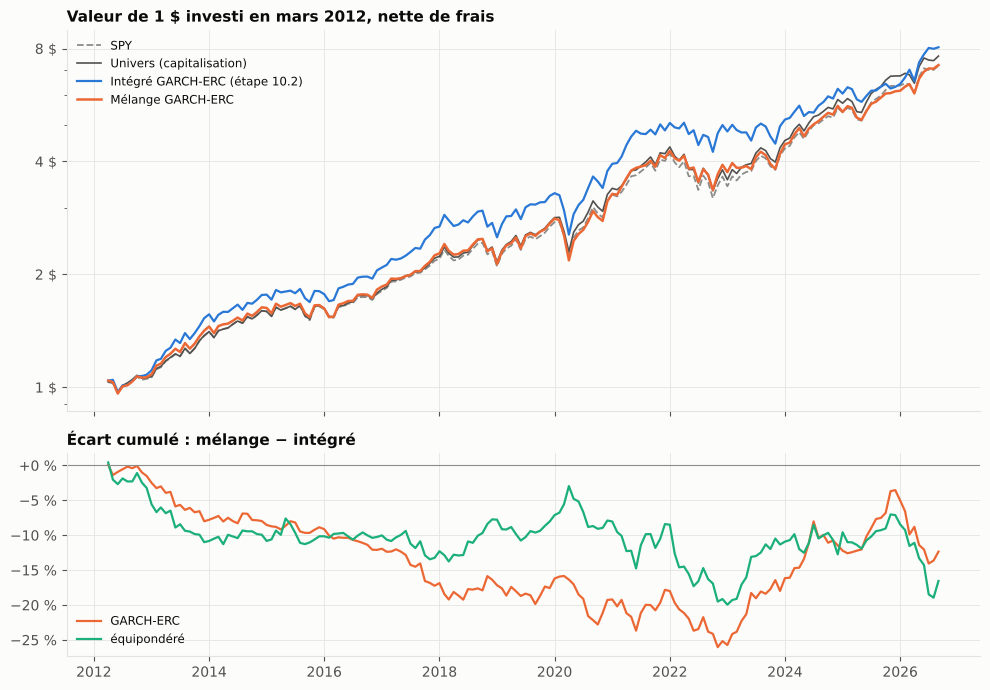

In [25]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1.6]})
d = periode.to_timestamp(how="end")
traces = [("SPY", GRIS, "--", 1.3), ("Univers (capitalisation)", TEXTE2, "-", 1.2),
          ("Intégré GARCH-ERC (étape 10.2)", BLEU, "-", 1.6), ("Mélange GARCH-ERC", ORANGE, "-", 1.8)]
for nom, couleur, style, lw in traces:
    ax1.plot(d, (1 + series[nom].reindex(periode)).cumprod(), color=couleur, ls=style, lw=lw, label=nom)
for (nom, bench), couleur, lib in [(("Mélange GARCH-ERC", "Intégré GARCH-ERC (étape 10.2)"), ORANGE, "GARCH-ERC"),
                                   (("Mélange équipondéré", "Intégré équipondéré (étape 9)"), AQUA, "équipondéré")]:
    ax2.plot(d, 100 * (series[nom] - series[bench]).reindex(periode).cumsum(), color=couleur, lw=1.6, label=lib)
ax2.axhline(0, color=GRIS, lw=0.8)
ax1.set_yscale("log")
ax1.set_yticks([1, 2, 4, 8])
ax1.yaxis.set_major_formatter(virgule("{:.0f} $"))
ax1.yaxis.set_minor_formatter(plt.NullFormatter())
ax1.set_title("Valeur de 1 $ investi en mars 2012, nette de frais")
ax1.legend(loc="upper left", fontsize=8.5)
ax2.yaxis.set_major_formatter(virgule("{:+.0f} %"))
ax2.set_title("Écart cumulé : mélange − intégré")
ax2.legend(loc="lower left", fontsize=8.5)
ax2.xaxis.set_major_locator(mdates.YearLocator(2))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
sauver(fig, "paniers_backtest.png")
plt.show()

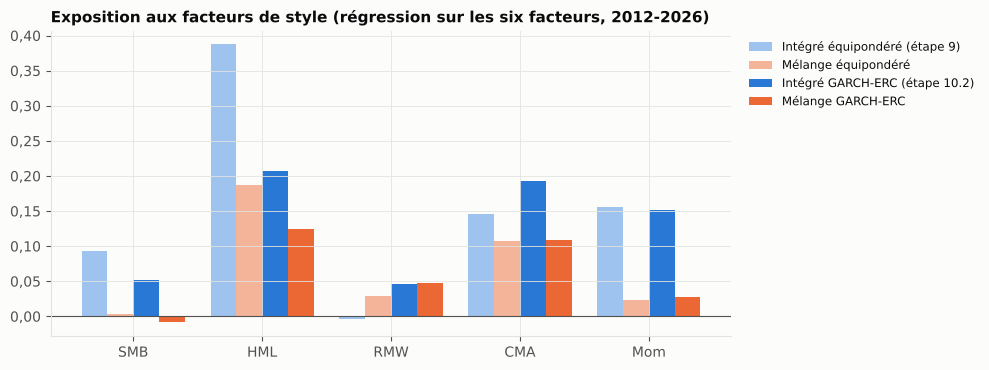

In [26]:
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(FACT))
larg = 0.2
for j, (nom, couleur) in enumerate([("Intégré équipondéré (étape 9)", "#9dc3ee"), ("Mélange équipondéré", "#f4b49a"),
                                    ("Intégré GARCH-ERC (étape 10.2)", BLEU), ("Mélange GARCH-ERC", ORANGE)]):
    ax.bar(x + (j - 1.5) * larg, expositions.loc[nom, FACT], width=larg, color=couleur, label=nom)
ax.axhline(0, color=TEXTE2, lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(FACT)
ax.yaxis.set_major_formatter(virgule("{:.2f}"))
ax.set_title("Exposition aux facteurs de style (régression sur les six facteurs, 2012-2026)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8.5)
fig.tight_layout()
sauver(fig, "paniers_expositions.png")
plt.show()